In [2]:
import pandas as pd

DATA_PATH = "../data/raw/"

orders = pd.read_csv(DATA_PATH + "orders.csv")
order_products_prior = pd.read_csv(DATA_PATH + "order_products__prior.csv")
order_products_train = pd.read_csv(DATA_PATH + "order_products__train.csv")
products = pd.read_csv(DATA_PATH + "products.csv")
aisles = pd.read_csv(DATA_PATH + "aisles.csv")
departments = pd.read_csv(DATA_PATH + "departments.csv")

print("orders:", orders.shape)
print("order_products_prior:", order_products_prior.shape)
print("order_products_train:", order_products_train.shape)
print("products:", products.shape)
print("aisles:", aisles.shape)
print("departments:", departments.shape)

orders: (3421083, 7)
order_products_prior: (32434489, 4)
order_products_train: (1384617, 4)
products: (49688, 4)
aisles: (134, 2)
departments: (21, 2)


In [6]:
orders.head()


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


In [7]:
order_products_prior.head()

,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


In [8]:
products.head()

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


In [9]:
aisles.head()

,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation


In [10]:
departments.head()

,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol


In [11]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   eval_set                str    
 3   order_number            int64  
 4   order_dow               int64  
 5   order_hour_of_day       int64  
 6   days_since_prior_order  float64
dtypes: float64(1), int64(5), str(1)
memory usage: 182.7 MB


In [12]:
order_detail = order_products_prior.merge(
    products,
    on="product_id",
    how="left"
)

order_detail.head()

,order_id,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id
0,2,33120,1,1,Organic Egg Whites,86,16
1,2,28985,2,1,Michigan Organic Kale,83,4
2,2,9327,3,0,Garlic Powder,104,13
3,2,45918,4,1,Coconut Butter,19,13
4,2,30035,5,0,Natural Sweetener,17,13


In [13]:
order_detail = order_detail.merge(
    aisles,
    on="aisle_id",
    how="left"
)

order_detail = order_detail.merge(
    departments,
    on="department_id",
    how="left"
)

order_detail.head()

,order_id,product_id,add_to_cart_order,reordered,product_name,aisle_id,department_id,aisle,department
0,2,33120,1,1,Organic Egg Whites,86,16,eggs,dairy eggs
1,2,28985,2,1,Michigan Organic Kale,83,4,fresh vegetables,produce
2,2,9327,3,0,Garlic Powder,104,13,spices seasonings,pantry
3,2,45918,4,1,Coconut Butter,19,13,oils vinegars,pantry
4,2,30035,5,0,Natural Sweetener,17,13,baking ingredients,pantry


In [14]:
order_detail["product_name"].value_counts().head(10)

product_name
Banana                    472565
Bag of Organic Bananas    379450
Organic Strawberries      264683
Organic Baby Spinach      241921
Organic Hass Avocado      213584
Organic Avocado           176815
Large Lemon               152657
Strawberries              142951
Limes                     140627
Organic Whole Milk        137905
Name: count, dtype: int64

In [15]:
order_detail["department"].value_counts()

department
produce            9479291
dairy eggs         5414016
snacks             2887550
beverages          2690129
frozen             2236432
pantry             1875577
bakery             1176787
canned goods       1068058
deli               1051249
dry goods pasta     866627
household           738666
breakfast           709569
meat seafood        708931
personal care       447123
babies              423802
international       269253
alcohol             153696
pets                 97724
missing              69145
other                36291
bulk                 34573
Name: count, dtype: int64

In [16]:
order_detail["aisle"].value_counts().head(10)

aisle
fresh fruits                     3642188
fresh vegetables                 3418021
packaged vegetables fruits       1765313
yogurt                           1452343
packaged cheese                   979763
milk                              891015
water seltzer sparkling water     841533
chips pretzels                    722470
soy lactosefree                   638253
bread                             584834
Name: count, dtype: int64

In [17]:
orders["order_hour_of_day"].value_counts().sort_index()

order_hour_of_day
0      22758
1      12398
2       7539
3       5474
4       5527
5       9569
6      30529
7      91868
8     178201
9     257812
10    288418
11    284728
12    272841
13    277999
14    283042
15    283639
16    272553
17    228795
18    182912
19    140569
20    104292
21     78109
22     61468
23     40043
Name: count, dtype: int64

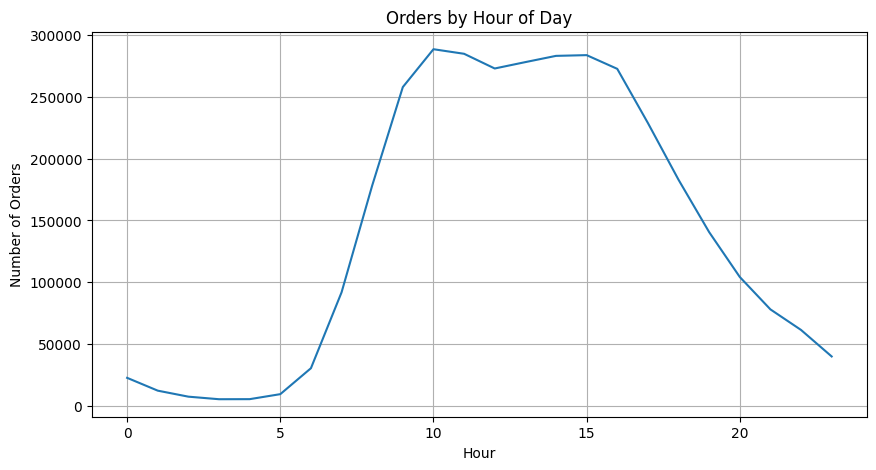

In [18]:
import matplotlib.pyplot as plt

hourly_orders = orders["order_hour_of_day"].value_counts().sort_index()

plt.figure(figsize=(10,5))
plt.plot(hourly_orders.index, hourly_orders.values)

plt.title("Orders by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Orders")

plt.grid(True)
plt.show()

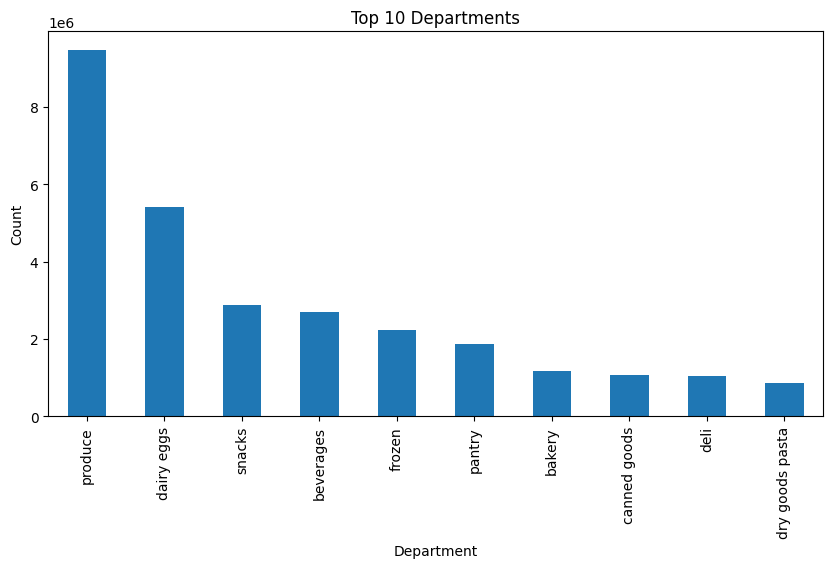

In [19]:
top_departments = order_detail["department"].value_counts().head(10)

plt.figure(figsize=(10,5))
top_departments.plot(kind="bar")

plt.title("Top 10 Departments")
plt.xlabel("Department")
plt.ylabel("Count")

plt.show()

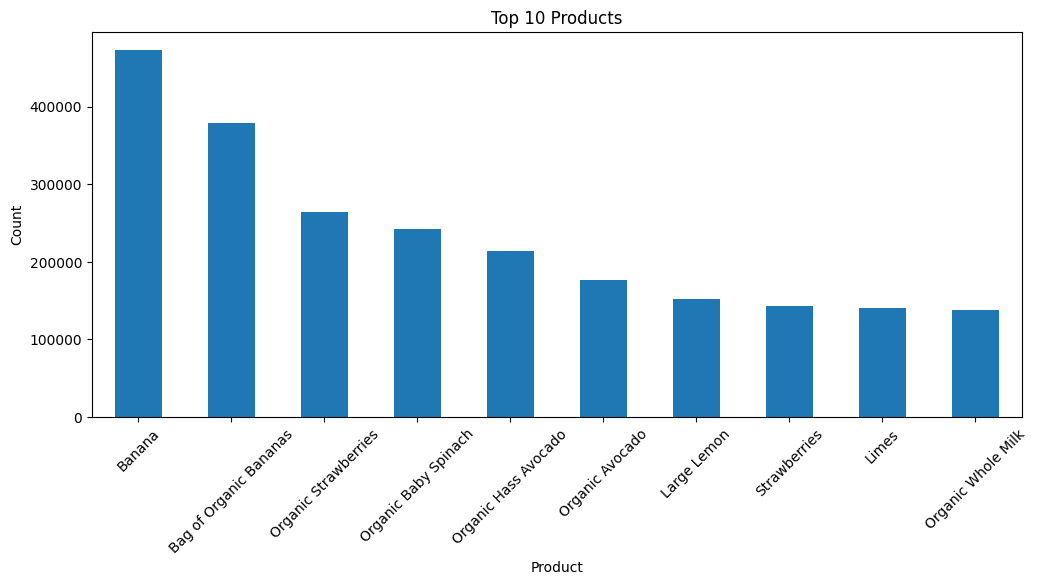

In [20]:
top_products = order_detail["product_name"].value_counts().head(10)

plt.figure(figsize=(12,5))
top_products.plot(kind="bar")

plt.title("Top 10 Products")
plt.xlabel("Product")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()